In [322]:
import pandas as pd
import sys
from pathlib import Path

columns = [
    "class", "cap_shape", "cap_surface", "cap_color",
    "bruises", "odor", "gill_attachment", "gill_spacing",
    "gill_size", "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above", "stalk_surface_below",
    "stalk_color_above", "stalk_color_below", "veil_type",
    "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

df = pd.read_csv("data/agaricus-lepiota.data", header=None, names=columns)

Eg starta med å fyrst lage ein kopi av den orginale fila.
Sidan boka seier at det kan bli missvisande å teste modellen på data den har lært ifrå, skilde eg av 20% til test etter modellen har vorte trent.

In [ ]:
from sklearn.model_selection import train_test_split
#Kopi av data
data = df.copy()

#Ukjende verdiar til eigen kategori, sidan median og gjennomsnitt ikkje er mogleg når vi har med tekst å gjere.
#Eller setje inn den det er mest av?
data = data.replace("?", "unknown")

#Skil kjenneteikn frå målvariabel, slik at modellen ikkje skal få tilgong til det den skal prediktere.
#Supervised learning 
"""
X = data.drop(columns=["class"])
y = data["class"] 
"""
all_features = data.drop(columns=["class"])
selected_features = [
    "stalk_root", "odor", "bruises",
    "spore_print_color","stalk_surface_below",
    "cap_surface",  "cap_shape","ring_number",
    "gill_size"  
] # - "veil_type","stalk_color_above","stalk_color_below","veil_color","ring_type","population", "habitat",
  #   "cap_color","gill_attachment", "gill_spacing", "gill_color", "stalk_shape","stalk_surface_above"
  #   

X = data[selected_features]
y = data["class"]

print("Tal på kjenneteikn:", X.shape[1])
print("Tal på målverdiar:", y.shape[0])
print("Ukjende verdiar:", (data == "?").sum().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treningsrader:", len(X_train))
print("Testrader:", len(X_test))

Tal på kjenneteikn: 9
Tal på målverdiar: 8124
Ukjende verdiar: 0
Treningsrader: 6499
Testrader: 1625


Å trene modellen

Pipeline

In [324]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
#Dele inn i til dømes 10 kjenneteikn? Til dømes odor kan ve vannskeleg å dømme ifrå. Kva skal vi ta med i nettsida?
#feature importance! Kan brukast til å sjekke kva dei ulike paramenterane har av innverknad.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            X.columns.tolist()
        )
    ]
)
#Testing seier max_depth=7 er best. Sjå bilete.
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=7,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Modellen er ferdig trena!")

Modellen er ferdig trena!


Accuracy

Accuracy: 1.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



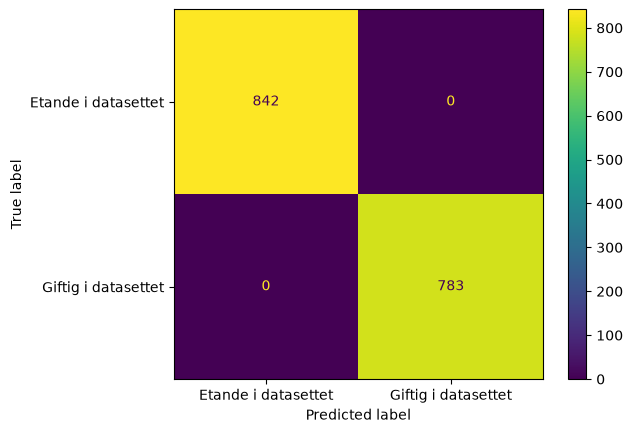

In [325]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["e", "p"],
    display_labels=["Etande i datasettet", "Giftig i datasettet"]
)

plt.show()

K-fold cross validation
For å teste accuracy.

In [326]:
from sklearn.model_selection import cross_val_score

# Cross-validation, 5
cv_scores = cross_val_score(model, X_train, y_train, cv=5)

print("Cross-Validation Scores:", cv_scores)
print(f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")

Cross-Validation Scores: [0.99846154 1.         1.         1.         1.        ]
Mean CV Accuracy: 99.97% (+/- 0.06%)


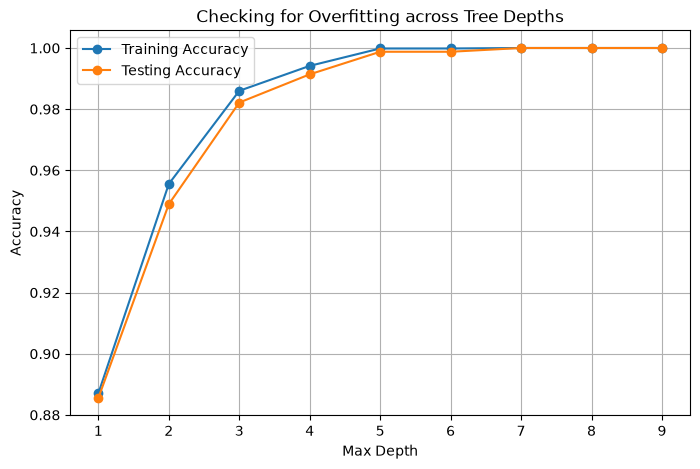

In [327]:
import matplotlib.pyplot as plt

depths = range(1, 10)
train_accuracies = []
test_accuracies = []

for depth in depths:
    # Build model with specific depth
    temp_model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    
    temp_model.fit(X_train, y_train)
    
    train_accuracies.append(temp_model.score(X_train, y_train))
    test_accuracies.append(temp_model.score(X_test, y_test))

# Plot results
plt.figure(figsize=(8, 5))
plt.plot(depths, train_accuracies, label="Training Accuracy", marker="o")
plt.plot(depths, test_accuracies, label="Testing Accuracy", marker="o")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Checking for Overfitting across Tree Depths")
plt.legend()
plt.grid(True)
plt.show()

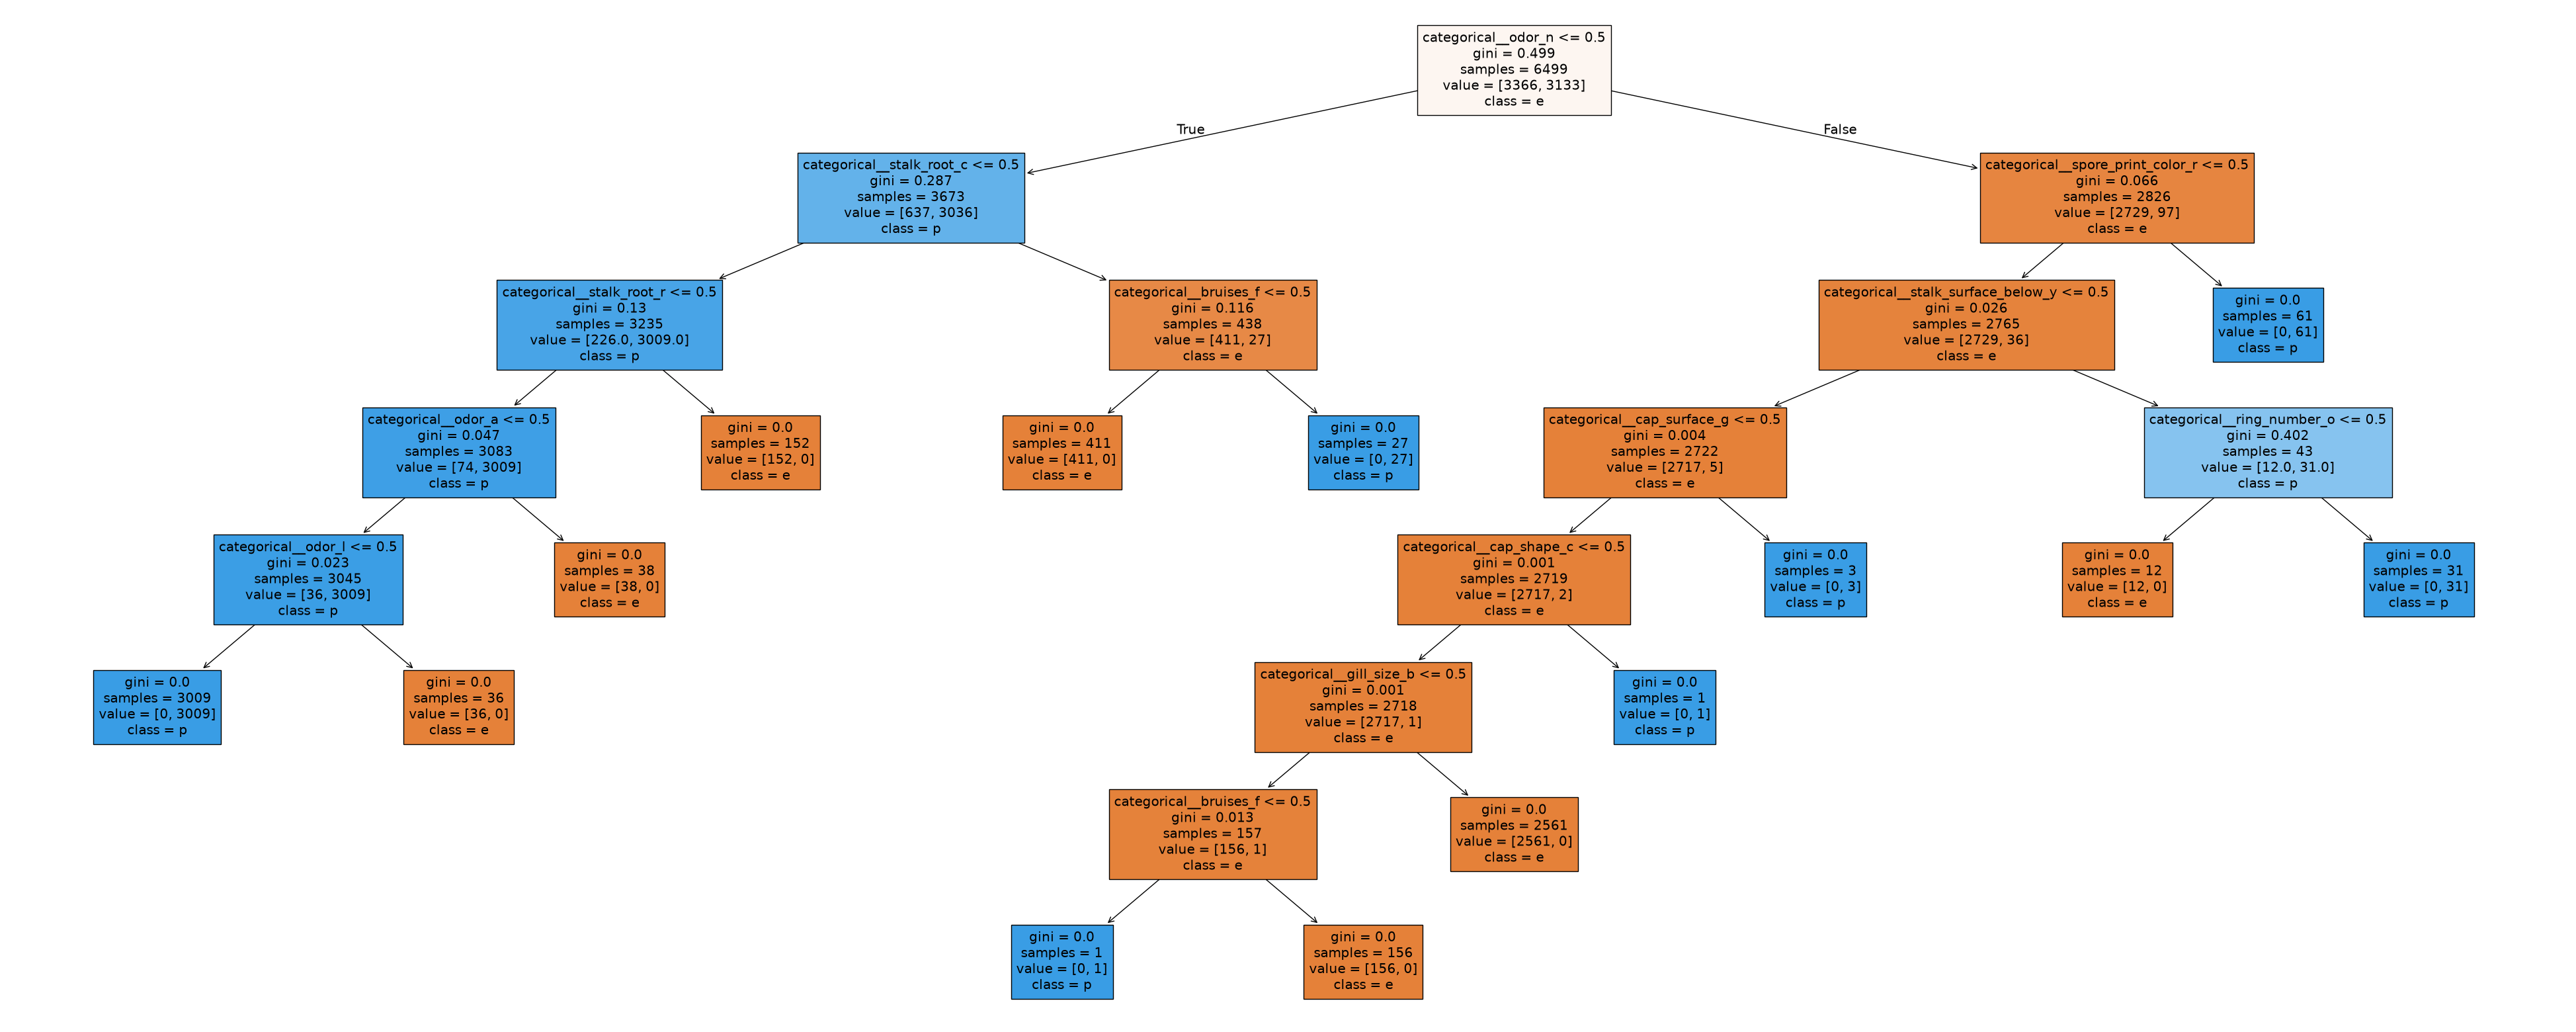

In [328]:
from sklearn.tree import plot_tree

#Extract feature names after OneHotEncoding
feature_names = model.named_steps['preprocessing'].get_feature_names_out()

plt.figure(figsize=(50, 20))
plot_tree(
    model.named_steps['classifier'],
    feature_names=feature_names,
    class_names=['e', 'p'],
    filled=True,
    max_depth=7  # Sjå heile treet
)
plt.show()

In [ ]:
Testradar som òg finst i trening

In [329]:
train_rows = set(
    X_train.astype(str).agg("|".join, axis=1)
)

test_rows = set(
    X_test.astype(str).agg("|".join, axis=1)
)

print(
    "Unike testradar som òg finst i trening:",
    len(train_rows & test_rows)
)

Unike testradar som òg finst i trening: 188


In [330]:
print("class" in X.columns)
print(X.shape)
print(y.shape)

False
(8124, 9)
(8124,)


In [331]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy per deling:", scores)
print("Gjennomsnitt:", scores.mean())
print("Lågaste resultat:", scores.min())

Accuracy per deling: [1. 1. 1. 1. 1.]
Gjennomsnitt: 1.0
Lågaste resultat: 1.0


Lagre modellen (henta frå boka):

In [ ]:
from joblib import Parallel, delayed
import joblib

# Save the model as a pickle in a file
joblib.dump(model, 'dt.pkl')

# Load the model from the file
#knn_from_joblib = joblib.load('filename.pkl')

# Use the loaded model to make predictions
#knn_from_joblib.predict(X_test)

['dt.pkl']